# Acoustic Expander — Time-Varying Inlet Pressure

Same model as `Acoustic_Expander_22.ipynb`, but with a ramp inlet pressure:
$$P_{\rm in}(t) = 600\,000 + 200\,000 \cdot \tanh(\lambda t) \quad [\text{Pa}]$$
simulated for $\lambda \in \{2, 1, 0.5\}$.

In [21]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib as mpl
import matplotlib.pyplot as plt

# ── Global academic plot style (Times New Roman / STIX) ──────────────────────

## Parameters (identical to baseline notebook)

In [22]:
# Fluid properties
gamma = 1.41
R     = 287       # J/(kg·K)
cp    = 1050      # J/(kg·K)
cv    = 744       # J/(kg·K)

# Baseline pressures (Pa)
P_in_base = 6e5   # P_in at t=0  (ramp starts here)
P_out     = 5.45e5
P0        = 5.725e5   # initial average pressure for passive volume

# Temperature
T_in = 300   # K
T0   = T_in

# Geometry
A_neck  = 2.85e-4   # m²
L_neck  = 0.15      # m
m_gas   = 0.0015    # kg
V0_cv   = 5.91e-5   # m³
V0_pass = 3.93e-4   # m³

# Damping
b_gas = 0.01        # kg/s

# Reed valve parameters
zeta     = 0.6
dP_inlet = P_in_base - P_out
dP_max   = dP_inlet / (2 * zeta)   # symmetric
dP_max_out = dP_max
m_max    = 0.001   # kg/s

# Time span and resolution
t_span = (0.0, 30.0)         # seconds
n_eval = 3_000_0000
t_eval = np.linspace(*t_span, n_eval)

# Initial conditions
x0    = 0.01 * L_neck   # small displacement
v0_ic = -5.0             # m/s
M0_cv = P0 * V0_cv / (R * T0)
E0_cv = cv * M0_cv * T0
y0    = [x0, v0_ic, M0_cv, E0_cv]

## Helper functions

In [23]:
def P_in_ramp(t, lam):
    return 600_000.0 + 50_000.0 * (np.tanh(lam * (t-4))) + 50_000.0*np.tanh(lam*4)


def reed_flow(dP, m_max, dP_max):
    """Mass flow through a reed valve (positive = flow from high to low pressure)."""
    u = dP / dP_max
    if 0 < dP < dP_max:
        return m_max * (1 - u) * np.sqrt(u)
    elif dP <= 0:
        return -m_max * (1 - u) * np.sqrt(abs(u))
    else:
        return 0.0


def make_ode(lam):
    """Return the ODE function for a given ramp rate lambda."""
    def ode(t, y):
        x, v, M_cv, E_cv = y

        V_cv  = V0_cv  + x * A_neck
        T_cv  = E_cv / (cv * M_cv) if M_cv > 0 else T0
        P_cv  = M_cv * R * T_cv / V_cv

        V_pass = V0_pass - x * A_neck
        P_pass = P0 * (V0_pass / V_pass) ** gamma if V_pass > 0 else P0

        Pin_t  = P_in_ramp(t, lam)
        dP_in  = Pin_t  - P_cv
        dP_out = P_cv   - P_out

        m_in  = reed_flow(dP_in,  m_max, dP_max)
        m_out = reed_flow(dP_out, m_max, dP_max_out)

        dV_cv_dt = A_neck * v
        dM_dt    = m_in - m_out
        dE_dt    = -P_cv * dV_cv_dt + m_in * cp * T_in - m_out * cp * T_cv

        dx_dt  = v
        dv_dt  = (P_cv - P_pass) * A_neck / m_gas - (b_gas / m_gas) * v

        return [dx_dt, dv_dt, dM_dt, dE_dt]
    return ode

## Run simulations for each λ

In [24]:
lambdas = [1/2, 0.51, 1]
results = {}

for lam in lambdas:
    print(f"Solving for λ = {lam} ...")
    sol = solve_ivp(
        make_ode(lam), t_span, y0,
        t_eval=t_eval, method='RK45',
        rtol=1e-6, atol=1e-8
    )
    t   = sol.t
    x   = sol.y[0]
    v   = sol.y[1]
    M_cv = sol.y[2]
    E_cv = sol.y[3]

    V_cv  = V0_cv + x * A_neck
    T_cv  = E_cv / (cv * M_cv)
    P_cv  = M_cv * R * T_cv / V_cv
    P_in_t = P_in_ramp(t, lam)

    results[lam] = dict(t=t, x=x, v=v, P_cv=P_cv, P_in_t=P_in_t)
    print(f"  Done. Final P_in = {P_in_t[-1]/1e5:.3f} bar")

Solving for λ = 0.5 ...
  Done. Final P_in = 6.982 bar
Solving for λ = 0.51 ...
  Done. Final P_in = 6.983 bar
Solving for λ = 1 ...
  Done. Final P_in = 7.000 bar


## Plots

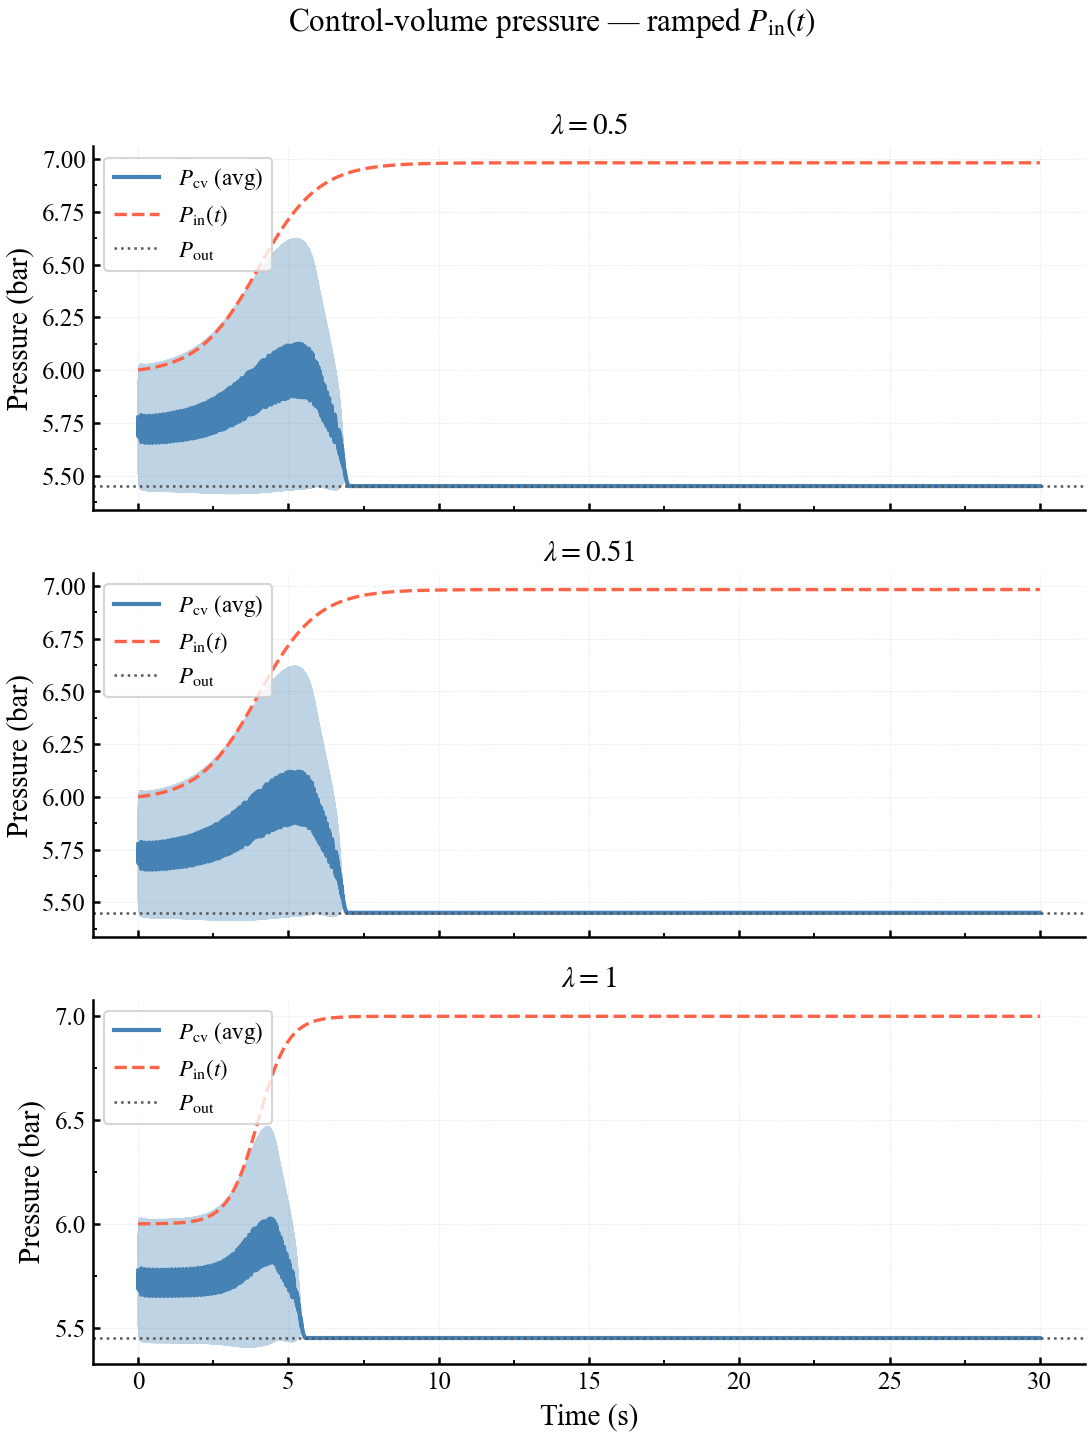

In [27]:
n_avg = 10_000   # block-averaging window

# ── One panel per λ ──────────────────────────────────────────────────────────
fig, axes = plt.subplots(len(lambdas), 1,
                         figsize=(7.5, 3.2 * len(lambdas)),
                         sharex=True)
if len(lambdas) == 1:
    axes = [axes]

for ax, lam in zip(axes, lambdas):
    r = results[lam]
    t, P_cv, P_in_t = r['t'], r['P_cv'], r['P_in_t']

    N = len(t)
    M = (N // n_avg) * n_avg
    t_avg  = t[:M].reshape(-1, n_avg).mean(axis=1)
    Pc_avg = P_cv[:M].reshape(-1, n_avg).mean(axis=1)

    ax.plot(t, P_cv / 1e5,    lw=0.5, alpha=0.35, color='steelblue')
    ax.plot(t_avg, Pc_avg / 1e5, lw=2.0, color='steelblue',
            label=r'$P_{\mathrm{cv}}$ (avg)')
    ax.plot(t, P_in_t / 1e5, lw=1.6, ls='--', color='tomato',
            label=r'$P_{\mathrm{in}}(t)$')
    ax.axhline(P_out / 1e5,  lw=1.2, ls=':',  color='#555555',
               label=r'$P_{\mathrm{out}}$')

    ax.set_ylabel('Pressure (bar)')
    ax.set_title(rf'$\lambda = {lam}$')
    ax.legend(loc='upper left')
    ax.grid(True, lw=0.5, alpha=0.35, linestyle=':')
    from matplotlib.ticker import AutoMinorLocator
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))

axes[-1].set_xlabel('Time (s)')
fig.suptitle(r'Control-volume pressure — ramped $P_{\mathrm{in}}(t)$',
             fontsize=15, y=1.01)
fig.tight_layout()
plt.savefig('time_varying_Pin_pressure.pdf')
plt.show()

## Effect of maximum reed mass-flow $\dot{m}_{\max}$ at fixed $\lambda = 0.5$

$\lambda = 0.5$ is held constant; $\dot{m}_{\max} \in \{0.001,\, 0.002,\, 0.003\}$ kg/s.

In [36]:
def make_ode_mmax(lam, m_max_val):
    """ODE factory: same physics as make_ode but with an explicit m_max argument."""
    def ode(t, y):
        x, v, M_cv, E_cv = y

        V_cv   = V0_cv  + x * A_neck
        T_cv   = E_cv / (cv * M_cv) if M_cv > 0 else T0
        P_cv   = M_cv * R * T_cv / V_cv

        V_pass = V0_pass - x * A_neck
        P_pass = P0 * (V0_pass / V_pass) ** gamma if V_pass > 0 else P0

        Pin_t  = P_in_ramp(t, lam)
        dP_in  = Pin_t - P_cv
        dP_out = P_cv  - P_out

        m_in  = reed_flow(dP_in,  m_max_val, dP_max)
        m_out = reed_flow(dP_out, m_max_val, dP_max_out)

        dV_cv_dt = A_neck * v
        dM_dt    = m_in - m_out
        dE_dt    = -P_cv * dV_cv_dt + m_in * cp * T_in - m_out * cp * T_cv

        dx_dt = v
        dv_dt = (P_cv - P_pass) * A_neck / m_gas - (b_gas / m_gas) * v

        return [dx_dt, dv_dt, dM_dt, dE_dt]
    return ode


# ── Run ──────────────────────────────────────────────────────────────────────
lam_fixed  = 0.5
mmax_vals  = [0.001, 0.002]
results_mm = {}

for mm in mmax_vals:
    print(f"Solving for m_max = {mm:.3f} kg/s ...")
    sol = solve_ivp(
        make_ode_mmax(lam_fixed, mm), t_span, y0,
        t_eval=t_eval, method='RK45',
        rtol=1e-6, atol=1e-8
    )
    t_s    = sol.t
    x_s    = sol.y[0]
    v_s    = sol.y[1]
    M_cv_s = sol.y[2]
    E_cv_s = sol.y[3]

    V_cv_s  = V0_cv + x_s * A_neck
    T_cv_s  = E_cv_s / (cv * M_cv_s)
    P_cv_s  = M_cv_s * R * T_cv_s / V_cv_s
    P_in_ts = P_in_ramp(t_s, lam_fixed)

    results_mm[mm] = dict(t=t_s, x=x_s, v=v_s, P_cv=P_cv_s, P_in_t=P_in_ts)
    print(f"  Done.")


Solving for m_max = 0.001 kg/s ...
  Done.
Solving for m_max = 0.002 kg/s ...
  Done.


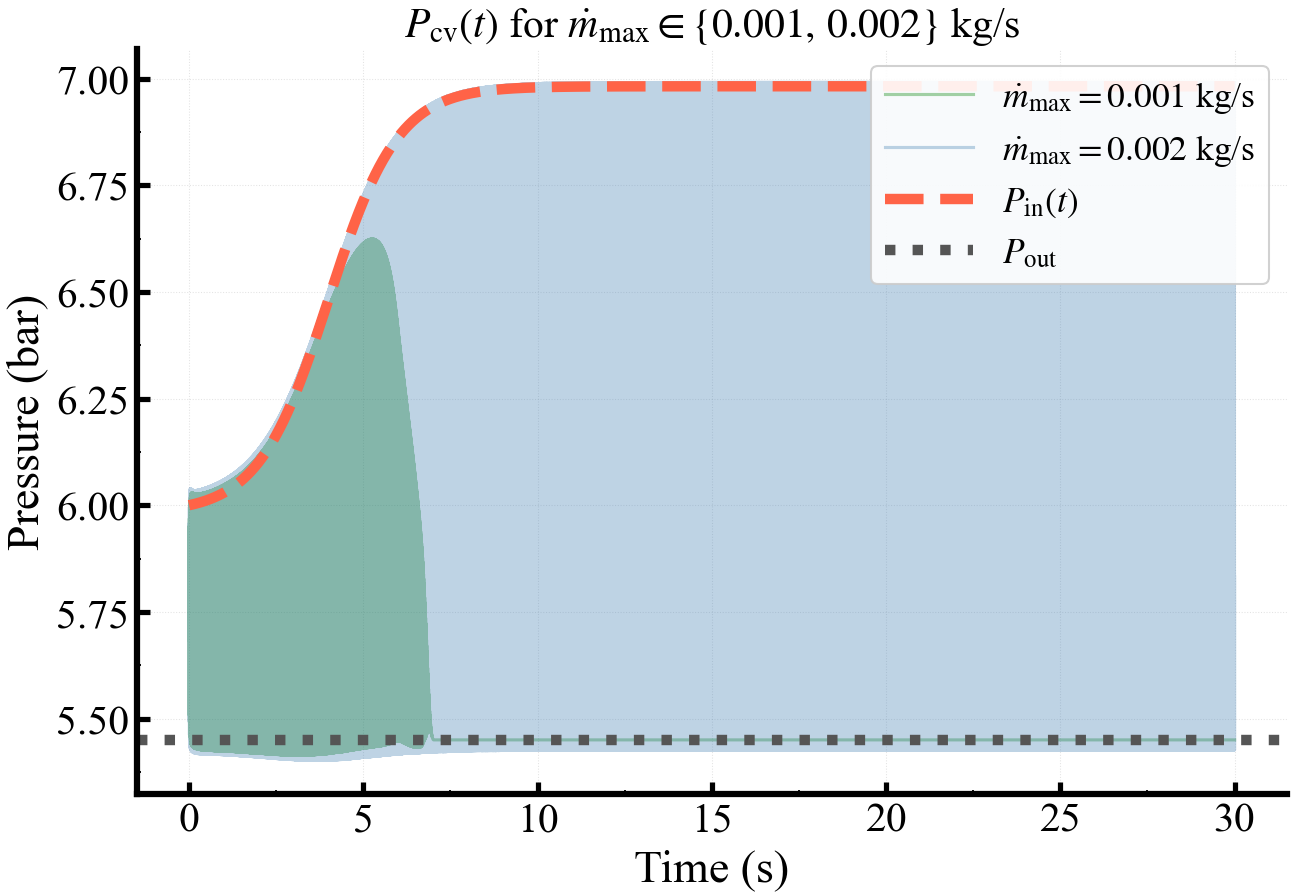

In [44]:
from matplotlib.ticker import AutoMinorLocator

colors_mm  = ['green', 'steelblue']
alphas_mm  = [0.35, 0.35]

with mpl.rc_context(rc_reed):
    fig, ax = plt.subplots(figsize=(9, 6.5))

    for mm, col, alp in zip(mmax_vals, colors_mm, alphas_mm):
        r = results_mm[mm]
        t, P_cv, P_in_t = r['t'], r['P_cv'], r['P_in_t']

        ax.plot(t, P_cv / 1e5, lw=1.5, alpha=alp, color=col,
                label=rf"$\dot{{m}}_\mathrm{{max}} = {mm:.3f}$ kg/s")

    ax.plot(t, P_in_t / 1e5, lw=5.0, ls='--', color='tomato',
            label=r'$P_\mathrm{in}(t)$')
    ax.axhline(P_out / 1e5, lw=5.0, ls=':', color='#555555',
               label=r'$P_\mathrm{out}$')

    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Pressure (bar)')
    ax.set_title(r'$P_\mathrm{cv}(t)$ for $\dot{m}_\mathrm{max} \in \{0.001,\,0.002\}$ kg/s')
    ax.legend(loc='upper right', framealpha=0.9, handlelength=2.5)
    ax.grid(True, lw=0.5, alpha=0.35, linestyle=':')
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.tight_layout()
    plt.savefig('time_varying_Pin_overlay.pdf', bbox_inches='tight')
    plt.savefig('time_varying_Pin_overlay.png', dpi=300, bbox_inches='tight')
    plt.show()

In [3]:
def reed_flow(dP_val, m_max_val, dP_max_val):
    """Mass flow rate through a reed valve (positive = flow from high to low pressure)."""
    u = dP_val / dP_max_val
    if 0 < dP_val < dP_max_val:
        return m_max_val * (1 - u) * np.sqrt(u)
    elif dP_val <= 0:
        return -m_max_val * (1 - u) * np.sqrt(abs(u))
    else:
        return 0.0
    
    
    

Saved → /Users/a1/Desktop/acoustic project/acoustic_expander/reed_flow_Pin=6bar.pdf  (zeta_eff = 0.6)


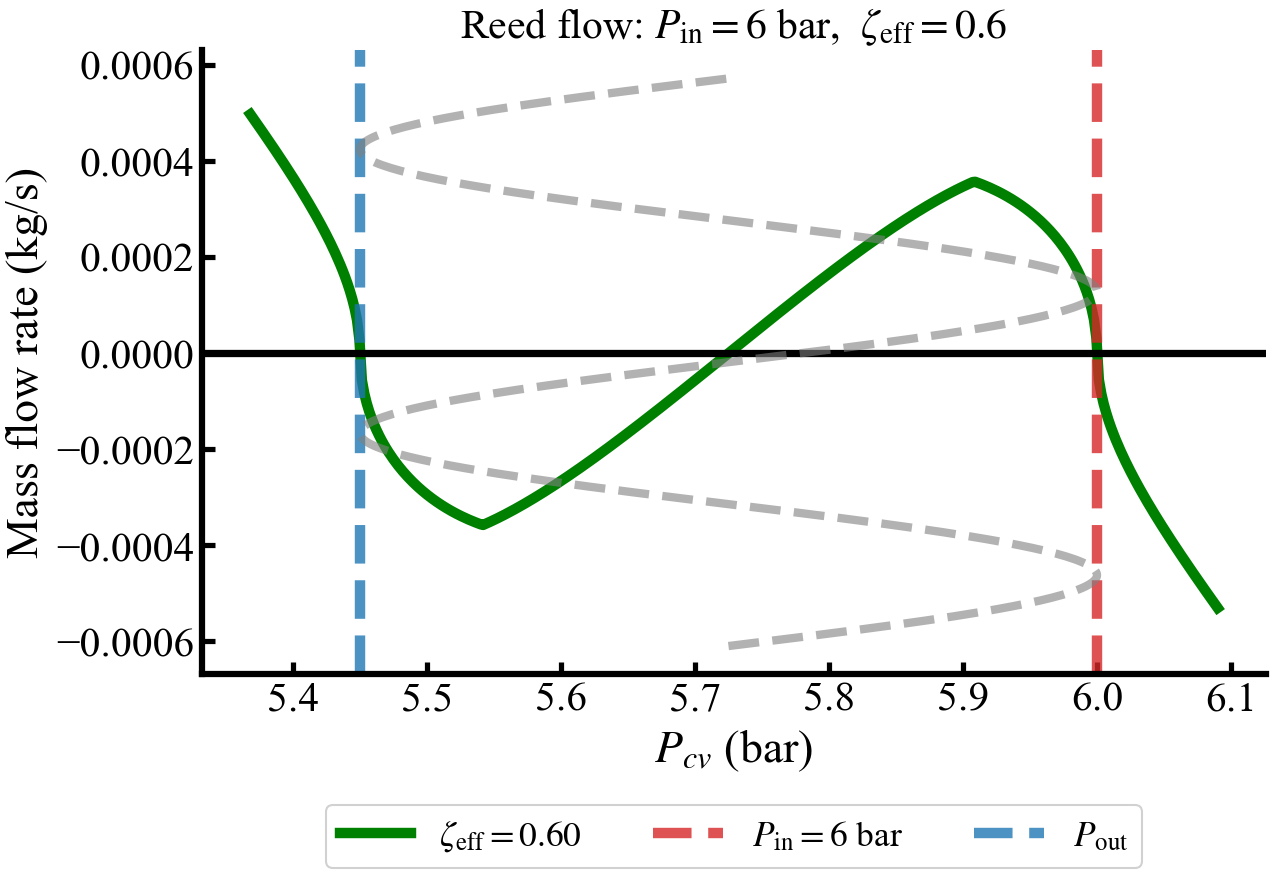

Saved → /Users/a1/Desktop/acoustic project/acoustic_expander/reed_flow_Pin=7bar.pdf  (zeta_eff = 1.7)


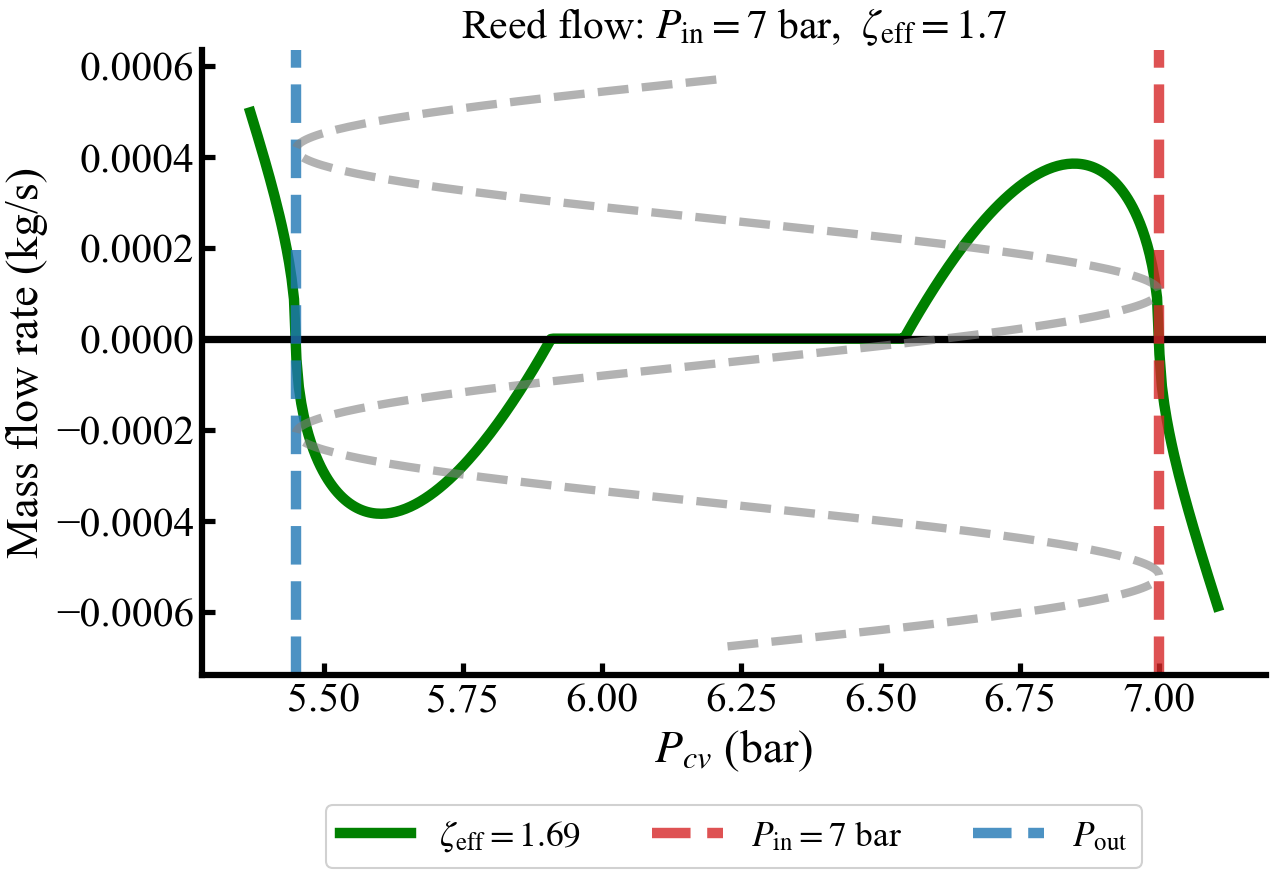

In [39]:
# ---- Reed flow curves: zeta=0.6 at P_in=6 bar, same valve at P_in=7 bar ----
#
#  Valve fixed: dP_max = (P_in_ref - P_out) / (2 * zeta_ref)
#  Effective zeta at P_in=7 bar: zeta_eff = (7bar - P_out) / (2 * dP_max)

import os

zeta_ref   = 0.6
P_in_ref   = 6e5
dP_max_v   = (P_in_ref - P_out) / (2 * zeta_ref)   # fixed valve property

P_in_vals  = [6e5, 7e5]

rc_reed = {
    "font.family":       "serif",
    "font.serif":        ["Times New Roman", "Times", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset":  "stix",
    "font.size":         20,
    "axes.labelsize":    22,
    "axes.titlesize":    20,
    "xtick.labelsize":   20,
    "ytick.labelsize":   20,
    "legend.fontsize":   17,
    "axes.linewidth":    3.0,
    "xtick.direction":   "in",
    "ytick.direction":   "in",
    "xtick.major.width": 2.5,
    "ytick.major.width": 2.5,
    "xtick.major.size":  6,
    "ytick.major.size":  6,
}

for P_in_v in P_in_vals:
    zeta_eff  = (P_in_v - P_out) / (2 * dP_max_v)
    P_cv_plot = np.linspace(P_out * 0.985, P_in_v * 1.015, 400)

    m_in_v  = np.array([reed_flow(P_in_v - p, m_max, dP_max_v) for p in P_cv_plot])
    m_out_v = np.array([-reed_flow(p - P_out,  m_max, dP_max_v) for p in P_cv_plot])
    m_tot_v = m_in_v + m_out_v

    # Fictitious oscillation sine wave between P_out and P_in
    P_mid   = (P_in_v + P_out) / 2
    P_amp   = (P_in_v - P_out) / 2
    y_lo    = m_tot_v.min() * 1.15
    y_hi    = m_tot_v.max() * 1.15
    t_osc   = np.linspace(0, 4 * np.pi, 400)
    x_osc   = (P_mid + P_amp * np.sin(t_osc)) / 1e5
    y_osc   = np.linspace(y_lo, y_hi, 400)

    with mpl.rc_context(rc_reed):
        fig, ax = plt.subplots(figsize=(9, 6.5))

        ax.plot(P_cv_plot / 1e5, m_tot_v, ls='-', color='green', lw=5.0,
                label=rf"$\zeta_\mathrm{{eff}} = {zeta_eff:.2f}$")
        ax.axhline(0, color='k', lw=3.5)
        ax.axvline(P_in_v / 1e5, ls='--', lw=5.0, color='tab:red',  alpha=0.8,
                   label=rf"$P_\mathrm{{in}} = {P_in_v/1e5:.0f}$ bar")
        ax.axvline(P_out  / 1e5, ls='--', lw=5.0, color='tab:blue', alpha=0.8,
                   label=r"$P_\mathrm{out}$")
        ax.plot(x_osc, y_osc, color='gray', lw=4.0, ls='--', alpha=0.6)

        ax.set_xlabel(r"$P_{cv}$ (bar)")
        ax.set_ylabel(r"Mass flow rate (kg/s)")
        ax.set_title(
            rf"Reed flow: $P_\mathrm{{in}} = {P_in_v/1e5:.0f}$ bar,  "
            rf"$\zeta_\mathrm{{eff}} = {zeta_eff:.1f}$"
        )
        ax.legend(ncol=4, framealpha=0.9, handlelength=2.0,
                  loc='upper center', bbox_to_anchor=(0.5, -0.18))
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        plt.tight_layout()
        fname = os.path.join(os.path.dirname(os.path.abspath("__file__")),
                             f"reed_flow_Pin={P_in_v/1e5:.0f}bar.pdf")
        plt.savefig(fname, dpi=300, bbox_inches="tight")
        print(f"Saved → {fname}  (zeta_eff = {zeta_eff:.1f})")
        plt.show()

Saved → /Users/a1/Desktop/acoustic project/acoustic_expander/reed_flow_overlay.pdf


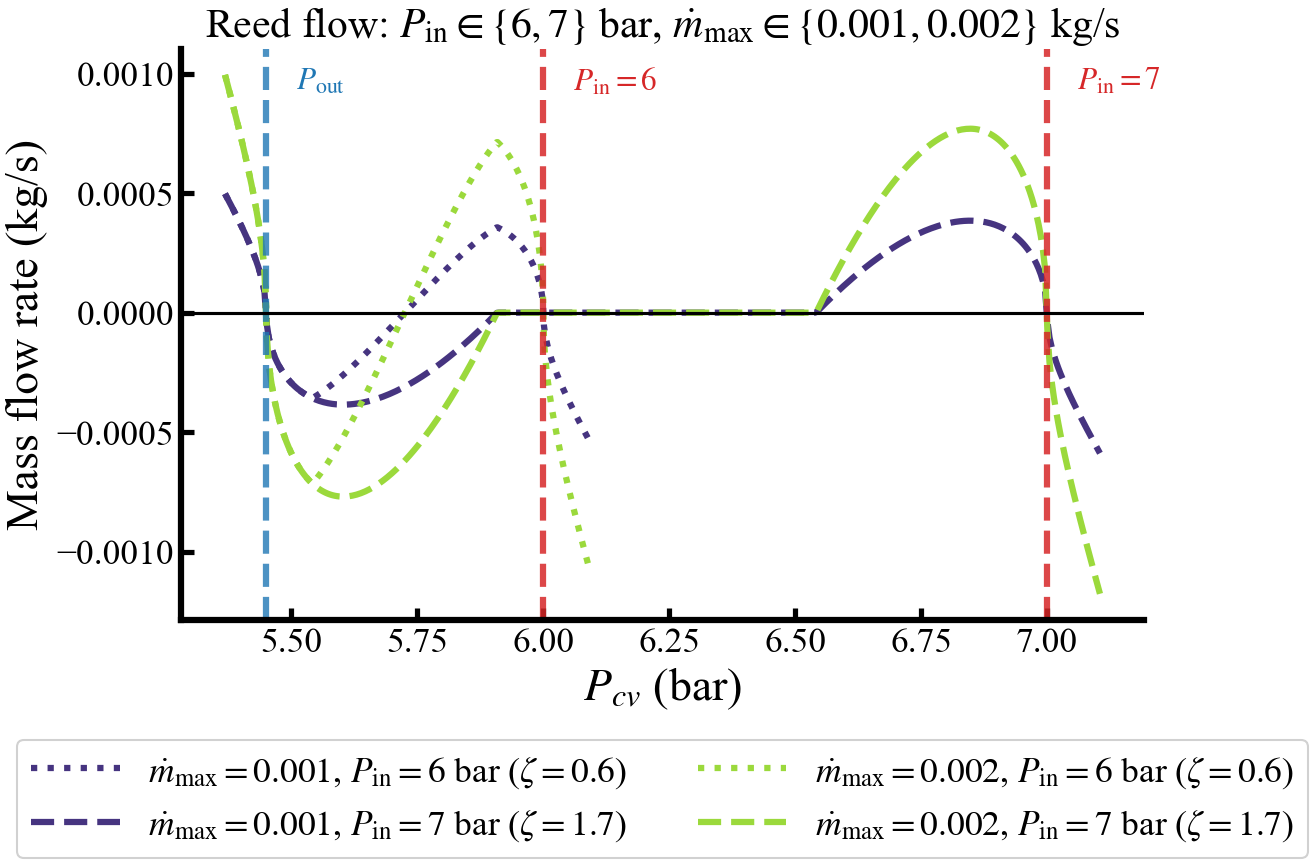

In [35]:
# ---- Overlay: both P_in × both m_max on the same plot ----
# Color = m_max,  line style = P_in (dotted=6 bar, dashed=7 bar)

mmax_vals      = [0.001, 0.002]
colors_mmax    = plt.cm.viridis(np.linspace(0.15, 0.85, len(mmax_vals)))
linestyles_Pin = {6e5: ':', 7e5: '--'}

with mpl.rc_context(rc_reed):
    fig, ax = plt.subplots(figsize=(9, 6.5))

    for mm, col in zip(mmax_vals, colors_mmax):
        for P_in_v in P_in_vals:
            zeta_eff  = (P_in_v - P_out) / (2 * dP_max_v)
            P_cv_plot = np.linspace(P_out * 0.985, P_in_v * 1.015, 400)
            ls        = linestyles_Pin[P_in_v]

            m_in_v  = np.array([reed_flow(P_in_v - p, mm, dP_max_v) for p in P_cv_plot])
            m_out_v = np.array([-reed_flow(p - P_out,  mm, dP_max_v) for p in P_cv_plot])
            m_tot_v = m_in_v + m_out_v

            ax.plot(P_cv_plot / 1e5, m_tot_v, ls=ls, color=col, lw=3.0,
                    label=rf"$\dot{{m}}_\mathrm{{max}}={mm:.3f}$, $P_\mathrm{{in}}={P_in_v/1e5:.0f}$ bar ($\zeta={zeta_eff:.1f}$)")

    top_transform = mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes)
    offset = 0.06   # bar units to the right

    for P_in_v in P_in_vals:
        ax.axvline(P_in_v / 1e5, ls='--', lw=3.0, color='tab:red', alpha=0.85,
                   label='_nolegend_')
        ax.text(P_in_v / 1e5 + offset, 0.97, rf"$P_\mathrm{{in}}={P_in_v/1e5:.0f}$",
                color='tab:red', fontsize=15, va='top', ha='left',
                transform=top_transform)

    ax.axvline(P_out / 1e5, ls='--', lw=3.0, color='tab:blue', alpha=0.8,
               label='_nolegend_')
    ax.text(P_out / 1e5 + offset, 0.97, r"$P_\mathrm{out}$",
            color='tab:blue', fontsize=15, va='top', ha='left',
            transform=top_transform)

    ax.axhline(0, color='k', lw=1.5)

    ax.set_xlabel(r"$P_{cv}$ (bar)")
    ax.set_ylabel(r"Mass flow rate (kg/s)")
    ax.set_title(r"Reed flow: $P_\mathrm{in} \in \{6,7\}$ bar, $\dot{m}_\mathrm{max} \in \{0.001, 0.002\}$ kg/s")
    ax.legend(ncol=2, framealpha=0.9, handlelength=2.5,
              loc='upper center', bbox_to_anchor=(0.5, -0.18))
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    fname = os.path.join(os.path.dirname(os.path.abspath("__file__")),
                         "reed_flow_overlay.pdf")
    plt.savefig(fname, dpi=300, bbox_inches="tight")
    print(f"Saved → {fname}")
    plt.show()